## A notebook for debug visualisation the Volleyball experiment

Do NOT work directly in this notebook -- instead, duplicate it and work in the copy!

#### Set up paths (add more cells as needed)

Andrius:

Åke:

Mikolaj:

#### Import libraries

In [44]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [45]:
import os
import sys
import numpy as np
import matplotlib.pyplot as pl
import astropy
from astropy import constants as SI

In [46]:
lib=top+'utilities/python'
if lib not in sys.path:
    sys.path.insert(0,lib)
import dispatch as dis
import dispatch.select as dse
import dispatch.graphics as dgr

#### Jump to  experiment main directory

In [47]:
os.chdir(top+'experiments/volleyball/')

### Read data

In [48]:
d = dispatch.snapshot(0, data="data/")

In [49]:
d.patches_in

<bound method snapshot.patches_in of <dispatch._dispatch.snapshot object at 0x2ae7b2ce6c40>>

In [50]:
# Create dictionary with id -> [`r`,`phi`,`theta`]

id2r = { p.id: round(np.sqrt(np.sum(p.position**2)) / SI.R_sun.value * 1e6, 4) for p in d.patches }
id2phi = { p.id: round(np.arctan(np.sqrt(np.sum(p.position[:2]**2)) / p.position[2]),2) for p in d.patches }
id2theta = { p.id: round(np.arccos( p.position[2] / np.sqrt(np.sum(p.position**2))),2) for p in d.patches }

In [51]:
uniqueR = set(id2r.values())
uniquePhi = set(id2phi.values())
uniqueTheta = set(id2theta.values())
print(f"We have Nr = { len(uniqueR) } unique R/r values with: [min/max] = {min(uniqueR):.3f} / {max(uniqueR):.3f}")
print(f"We have Np = { len(uniquePhi) } unique Phi values with: [min/max] = {np.rad2deg(min(uniquePhi)):.3f} / {np.rad2deg(max(uniquePhi)):.3f}")
print(f"We have Nt = { len(uniqueTheta) } unique Theta values with: [min/max] = {np.rad2deg(min(uniqueTheta)):.3f} / {np.rad2deg(max(uniqueTheta)):.3f}")

print(f"Total number of patches: {len(d.patches)} vs. Nr x Np x Nt = {len(uniqueR) * len(uniquePhi) * len(uniqueTheta)}")


We have Nr = 5 unique R/r values with: [min/max] = 0.730 / 0.901
We have Np = 200 unique Phi values with: [min/max] = -88.808 / 88.808
We have Nt = 197 unique Theta values with: [min/max] = 2.292 / 178.190
Total number of patches: 25320 vs. Nr x Np x Nt = 197000


In [52]:
# sphi = min(sorted(uniqueTheta))
# ids = [pid for pid, phi in id2phi.items() if sphi - 0.1 <=  phi <= sphi + 0.1]

sphi = min(sorted(uniquePhi))
ids = [pid for pid, phi in id2phi.items() if sphi - 0.02 <=  phi <= sphi + 0.02]

# ref_r = 0.9
# ids = [pid for pid, r in id2r.items() if ref_r - 0.1 <=  r <= ref_r + 0.1]
# for i in ids:
#    if d.patches[i].position[2] > 0:
#       print(d.patches[i].position)

# min(sorted(set([d.patches[i].position[2] for i in ids])))
# max(sorted(set([d.patches[i].position[2] for i in ids])))

print(f"Weee! We have {len(ids)} patches to plot!")

Weee! We have 640 patches to plot!


In [53]:
# Create dictionary with id -> [`r`,`phi`,`theta`]

id2z = { p.id: p.position[2] for p in d.patches }
uniqueZ = set(id2z.values())
uniqueZpos = set([ round(abs(x),2) for x in uniqueZ])

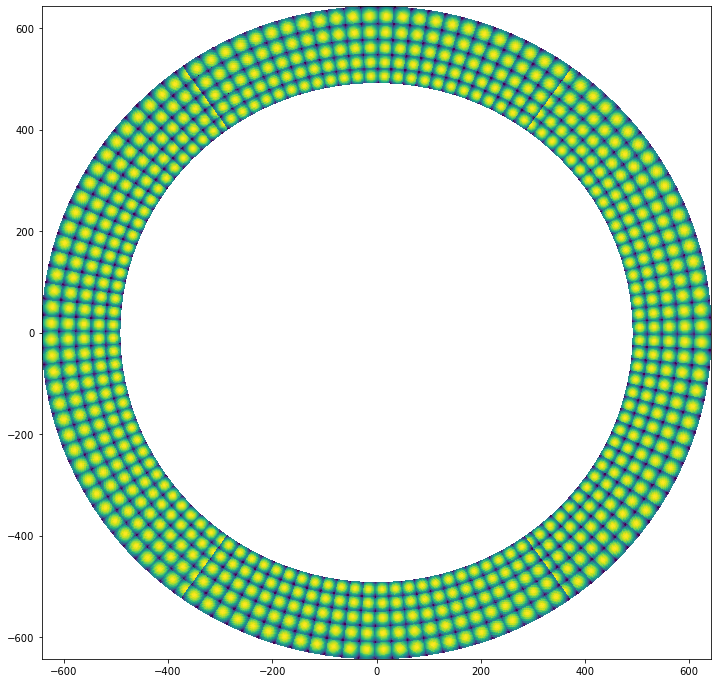

In [54]:
fig, ax = plt.subplots(figsize=(12,12))
for p in d.patches:
    if ( 10.0 <= round(abs(p.position[2]),2) <= 19.0):
        slice = np.log(p.var('e')[:, :, 10])
        X, Y = np.meshgrid(p.x[2:-3], p.y[2:-3])
        # [23.02.2022] After recent changes this shift is not needed anymore
        # X = X - p.position[0]
        # Y = Y - p.position[1]
        angle = np.arctan2(p.position[1] - 1.0,p.position[0])
        Xr = np.cos(angle)*X - np.sin(angle)*Y
        Yr = np.sin(angle)*X + np.cos(angle)*Y
        X = Xr + p.position[0]
        Y = Yr + p.position[1]
        ax.pcolormesh(X, Y, slice)

#         plt.savefig('uff.png')